# 7. Model interpretation — Figure 5

Save the five Figure 5A–C plots and their source data.


## Load matching results

In [1]:
from pathlib import Path
import sys

PROJECT_ROOT = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "mea_ml" / "io.py").is_file()
)
sys.path.insert(0, str(PROJECT_ROOT))

from mea_ml.plotting import save_png
from IPython.display import display
import json
import hashlib
import textwrap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize, LinearSegmentedColormap, to_rgba
from matplotlib.patches import Patch, Rectangle
from matplotlib.cbook import boxplot_stats
from sklearn.metrics import roc_auc_score
from scipy.stats import spearmanr

from mea_ml.io import ROOT as PROJECT_ROOT
SHAP_DIR=PROJECT_ROOT/"results/05_interpretation"
FAMILY_DIR=PROJECT_ROOT/"results/06_family_analysis"
ML_DIR=PROJECT_ROOT/"results/03_ml"
OUT_DIR=PROJECT_ROOT/"results/07_figure5"
OUT_DIR.mkdir(parents=True,exist_ok=True)
plt.rcParams.update({"font.size":10,"axes.titlesize":11,"axes.labelsize":10,"figure.dpi":300,
                    "axes.spines.top":False,"axes.spines.right":False,"legend.frameon":False})
AXIS_LINEWIDTH=1.5
PLOT_RANDOM_STATE=42
DECISION_THRESHOLD=0.5
ADDITIVITY_ATOL=1e-5
BOXPLOT_WHIS=1.5
SHAP_DIRECTION_ATOL=1e-12
FEATURE_LABEL_WIDTH=36

def require(path):
    if not path.exists():
        raise FileNotFoundError(
            f"Missing: {path.relative_to(PROJECT_ROOT)}\n"
            "Run notebooks 3, 5 and 6 before notebook 7."
        )
    return path
def read_table(folder,stem):
    return pd.read_csv(require(folder/f"{stem}.csv"),float_precision="round_trip")
shap_summary=json.loads(require(SHAP_DIR/"interpretation_summary.json").read_text())
family_analysis_summary=json.loads(require(FAMILY_DIR/"family_analysis_summary.json").read_text())
if (ML_DIR/"export_in_progress.json").exists():
    raise RuntimeError("03 export is incomplete. Finish 03, then rerun 05 and 06 before 07.")
ml_summary=json.loads(require(ML_DIR/"ml_summary.json").read_text(encoding="utf-8"))
training_seed=ml_summary.get("random_state", "unknown")
current_artifact_hash=hashlib.sha256(require(ML_DIR/"model_artifacts.joblib").read_bytes()).hexdigest()
current_bundle_hash=hashlib.sha256(require(PROJECT_ROOT/"results/01_dataset/training_bundle.joblib").read_bytes()).hexdigest()
expected_artifact_hash=ml_summary.get("export_sha256",{}).get("model_artifacts.joblib")
if expected_artifact_hash and current_artifact_hash != expected_artifact_hash:
    raise RuntimeError("03 model/summary files are from different runs. Complete 03 export, then rerun 05 and 06.")
expected_bundle_hash=ml_summary.get("training_bundle_sha256")
if expected_bundle_hash and current_bundle_hash != expected_bundle_hash:
    raise RuntimeError("The dataset has changed since training. Rerun 03, then 05 and 06 before 07.")
stale_notebooks=[]
for number, result_summary in [("05",shap_summary),("06",family_analysis_summary)]:
    saved_lineage=result_summary.get("lineage",{})
    if (saved_lineage.get("training_artifact_sha256") != current_artifact_hash or
        saved_lineage.get("training_bundle_sha256") != current_bundle_hash):
        stale_notebooks.append(number)
if stale_notebooks:
    raise RuntimeError(f"Current 03 training seed: {training_seed}. Results from notebook(s) "
                       f"{', '.join(stale_notebooks)} belong to a different run. "
                       "Rerun those notebooks through their export cells, then rerun 07.")
if shap_summary["lineage"] != family_analysis_summary["lineage"]:
    raise RuntimeError("05 and 06 have different saved settings. Rerun both using the current 03 results, then rerun 07.")
lineage=shap_summary["lineage"]
print("Training random seed from 03:",training_seed)
selected_model=shap_summary["selected_model_name"]
selected_feature_set=shap_summary["selected_feature_set"]
N_REPEATS=int(lineage["n_repeats"])
N_FITS=N_REPEATS*int(lineage["outer_n_splits"])

print("Figure 5:",selected_model,selected_feature_set,"|",N_FITS,"outer fits")


Training random seed from 03: 0
Figure 5: XGBoost mean+delta | 15 outer fits


## SHAP and family source data

In [2]:
shap_mean_df=read_table(SHAP_DIR,"shap_values_oof_mean")
shap_feature_ranking=read_table(SHAP_DIR,"shap_feature_ranking")
family_map=read_table(SHAP_DIR,"feature_family_map_primary")
feature_to_family=dict(zip(family_map.feature_name,family_map.feature_family))
def engineered_feature_to_family(name): return feature_to_family[name]
family_list=family_map.feature_family.drop_duplicates().tolist()
family_summary=read_table(FAMILY_DIR,"family_performance_summary")
family_repeat_metrics=read_table(FAMILY_DIR,"family_repeat_metrics")
full_auc=float(family_summary.query("feature_subset_name=='full'").pooled_roc_auc.iloc[0])
assert set(family_summary.query("analysis_type=='family_only'").feature_family)==set(family_list)
assert not family_summary.query("analysis_type in ['family_only','leave_one_family_out']").duplicated(['analysis_type','feature_family']).any()
assert shap_mean_df.sample_index.nunique()==family_analysis_summary["n_unique_wells"]
assert shap_mean_df.n_repeats.eq(N_REPEATS).all()
assert family_summary.query("analysis_type=='leave_one_family_out'").feature_family.nunique()==len(family_list)

prediction_audit=read_table(SHAP_DIR,"shap_prediction_audit_by_repeat")
prediction_audit_mean=read_table(SHAP_DIR,"shap_prediction_audit_mean")
explainer_audit=read_table(SHAP_DIR,"shap_explainer_audit")
shap_by_repeat=read_table(SHAP_DIR,"shap_values_oof")
ml_repeats=read_table(ML_DIR,"oof_predictions_by_repeat")
ml_main=read_table(ML_DIR,"oof_predictions_main")
selected_repeats=ml_repeats[
    (ml_repeats.model_name==selected_model)&(ml_repeats.feature_set==selected_feature_set)
].copy()
selected_main=ml_main[
    (ml_main.model_name==selected_model)&(ml_main.feature_set==selected_feature_set)
].copy()
keys=["sample_index","repeat_id","outer_fold_id"]
assert explainer_audit.output_space.eq("positive_probability").all(), "Figure 5 requires probability-scale SHAP from notebook 5."
assert len(explainer_audit)==N_FITS
assert not explainer_audit.duplicated(["outer_fold_id","repeat_id"]).any()
assert not prediction_audit.duplicated(["sample_index","repeat_id"]).any()
assert not selected_repeats.duplicated(["sample_index","repeat_id"]).any()
assert prediction_audit.groupby("sample_index").repeat_id.nunique().eq(N_REPEATS).all()
assert not shap_by_repeat.duplicated(keys+["feature_name"]).any()
assert not shap_mean_df.duplicated(["sample_index","feature_name"]).any()
n_features=shap_mean_df.feature_name.nunique()
assert shap_mean_df.groupby("sample_index").size().eq(n_features).all()
assert shap_by_repeat.groupby(keys).size().eq(n_features).all()

repeat_sums=(shap_by_repeat.groupby(keys,as_index=False).shap_value.sum()
             .rename(columns={"shap_value":"sum_saved_shap"}))
repeat_check=prediction_audit.merge(repeat_sums,on=keys,validate="one_to_one")
repeat_check=repeat_check.merge(
    selected_repeats[keys+["group_id","y_true","y_proba"]],on=keys,
    suffixes=("","_03"),validate="one_to_one")
assert len(repeat_check)==len(prediction_audit)==len(selected_repeats)
assert repeat_check.group_id.eq(repeat_check.group_id_03).all()
assert repeat_check.y_true.eq(repeat_check.y_true_03).all()
np.testing.assert_allclose(repeat_check.sum_saved_shap,repeat_check.shap_sum,rtol=0,atol=ADDITIVITY_ATOL)
np.testing.assert_allclose(repeat_check.base_value+repeat_check.sum_saved_shap,repeat_check.y_proba,rtol=0,atol=ADDITIVITY_ATOL)
np.testing.assert_allclose(repeat_check.y_proba,repeat_check.y_proba_03,rtol=0,atol=1e-6)
assert repeat_check.y_proba.between(0,1).all()

for row in explainer_audit.itertuples(index=False):
    background_groups=set(str(row.background_groups).split("|"))
    test_groups=set(str(row.test_groups).split("|"))
    assert not background_groups.intersection(test_groups)
    heldout=repeat_check[(repeat_check.outer_fold_id==row.outer_fold_id)&(repeat_check.repeat_id==row.repeat_id)]
    assert len(heldout)==int(row.n_test) and set(heldout.group_id.astype(str))==test_groups

recomputed_mean=(shap_by_repeat.groupby(["sample_index","feature_name"],as_index=False).shap_value.mean())
mean_check=shap_mean_df.merge(recomputed_mean,on=["sample_index","feature_name"],
                            suffixes=("","_recomputed"),validate="one_to_one")
assert len(mean_check)==len(shap_mean_df)
np.testing.assert_allclose(mean_check.shap_value,mean_check.shap_value_recomputed,rtol=0,atol=ADDITIVITY_ATOL)

well_meta=shap_mean_df[["sample_index","group_id","class","pair_stem","well","y_true"]].drop_duplicates()
assert not well_meta.sample_index.duplicated().any()
well_predictions=(prediction_audit.groupby("sample_index",as_index=False)
    .agg(base_value=("base_value","mean"),y_proba=("y_proba","mean"),
         n_repeats=("repeat_id","nunique")))
well_predictions=well_predictions.merge(well_meta,on="sample_index",validate="one_to_one")
mean_sums=shap_mean_df.groupby("sample_index",as_index=False).shap_value.sum().rename(columns={"shap_value":"shap_sum"})
well_predictions=well_predictions.merge(mean_sums,on="sample_index",validate="one_to_one").sort_values("sample_index").reset_index(drop=True)
well_predictions["reconstructed_probability"]=well_predictions.base_value+well_predictions.shap_sum
well_predictions["additivity_error"]=(well_predictions.reconstructed_probability-well_predictions.y_proba).abs()
assert len(well_predictions)==len(selected_main)==len(prediction_audit_mean)
np.testing.assert_allclose(well_predictions.reconstructed_probability,well_predictions.y_proba,rtol=0,atol=ADDITIVITY_ATOL)
reference=prediction_audit_mean.set_index("sample_index").loc[well_predictions.sample_index]
pooled=selected_main.set_index("sample_index").loc[well_predictions.sample_index]
np.testing.assert_allclose(well_predictions.base_value,reference.base_value,rtol=0,atol=ADDITIVITY_ATOL)
np.testing.assert_allclose(well_predictions.y_proba,reference.y_proba,rtol=0,atol=1e-6)
np.testing.assert_allclose(well_predictions.y_proba,pooled.y_proba,rtol=0,atol=1e-6)
assert np.array_equal(well_predictions.y_true.to_numpy(),pooled.y_true.to_numpy())
assert np.array_equal(well_predictions.group_id.astype(str).to_numpy(),pooled.group_id.astype(str).to_numpy())
well_predictions["y_pred"]=(well_predictions.y_proba>=DECISION_THRESHOLD).astype(int)
assert np.array_equal(well_predictions.y_pred.to_numpy(),pooled.y_pred.to_numpy())
assert np.isclose(roc_auc_score(well_predictions.y_true,well_predictions.y_proba),full_auc,atol=1e-6)

print(f"Verified {len(well_predictions)} wells × {N_REPEATS} OOF repeats; maximum mean additivity error = {well_predictions.additivity_error.max():.2e}")

def compute_shap_direction_by_fit(shap_table):
    rows=[]
    for (feat,fid),d in shap_table.groupby(["feature_name","outer_fold_id"],sort=True):
        assert d.repeat_id.nunique()==1
        x=pd.to_numeric(d.feature_value,errors="coerce").to_numpy(dtype=float)
        phi=pd.to_numeric(d.shap_value,errors="coerce").to_numpy(dtype=float)
        finite=np.isfinite(x)&np.isfinite(phi)
        x_valid,phi_valid=x[finite],phi[finite]
        rho=np.nan
        if len(x_valid)<3:
            status="insufficient_finite_pairs"
        elif np.ptp(x_valid)==0:
            status="constant_feature"
        elif np.ptp(phi_valid)<=SHAP_DIRECTION_ATOL:
            status="constant_shap"
        else:
            rho=float(spearmanr(x_valid,phi_valid).statistic)
            status="estimable" if np.isfinite(rho) else "undefined_correlation"
        rows.append({"feature_name":feat,"feature_family":engineered_feature_to_family(feat),
                     "outer_fold_id":int(fid),"repeat_id":int(d.repeat_id.iloc[0]),
                     "n_heldout_wells":len(d),"n_recording_groups":d.group_id.nunique(),
                     "n_finite_pairs":int(finite.sum()),"n_nonfinite_pairs":int((~finite).sum()),
                     "spearman_rho":rho,"direction_status":status,
                     "mean_abs_shap":float(np.mean(np.abs(phi_valid))) if len(phi_valid) else np.nan})
    return pd.DataFrame(rows)

shap_direction_by_fit=compute_shap_direction_by_fit(shap_by_repeat)
assert not shap_direction_by_fit.duplicated(["feature_name","outer_fold_id"]).any()
assert shap_direction_by_fit.groupby("feature_name").outer_fold_id.nunique().eq(N_FITS).all()
assert set(map(tuple,shap_direction_by_fit[["feature_name","outer_fold_id"]].to_numpy()))==set(
    map(tuple,shap_by_repeat[["feature_name","outer_fold_id"]].drop_duplicates().to_numpy()))
valid_rho=shap_direction_by_fit.spearman_rho.dropna()
assert valid_rho.between(-1,1).all()
print("Direction status across all features/fits:")
display(shap_direction_by_fit.direction_status.value_counts())

family_oof_mean=read_table(FAMILY_DIR,"family_oof_predictions_mean")
family_only_oof=family_oof_mean[family_oof_mean.analysis_type.eq("family_only")].copy()
assert set(family_only_oof.feature_family)==set(family_list)
assert not family_only_oof.duplicated(["sample_index","feature_family"]).any()
assert family_only_oof.n_repeats.eq(N_REPEATS).all()
assert np.isfinite(family_only_oof.y_proba).all() and family_only_oof.y_proba.between(0,1).all()
reference_wells=well_predictions.set_index("sample_index").sort_index()
for family,d in family_only_oof.groupby("feature_family"):
    d=d.set_index("sample_index").sort_index()
    assert d.index.equals(reference_wells.index), f"Incomplete OOF wells: {family}"
    assert d.y_true.eq(reference_wells.y_true).all()
    assert d.group_id.astype(str).eq(reference_wells.group_id.astype(str)).all()
    assert d.y_pred.eq(d.y_proba.ge(DECISION_THRESHOLD).astype(int)).all()
    reported_auc=float(family_summary.query("analysis_type == 'family_only'")
                       .set_index("feature_family").loc[family,"pooled_roc_auc"])
    assert np.isclose(roc_auc_score(d.y_true,d.y_proba),reported_auc,atol=1e-8)
full_family_oof=family_oof_mean[family_oof_mean.feature_subset_name.eq("full")].set_index("sample_index").sort_index()
assert full_family_oof.index.equals(reference_wells.index)
np.testing.assert_allclose(full_family_oof.y_proba,reference_wells.y_proba,rtol=0,atol=1e-6)

family_probabilities=family_only_oof.pivot(index="sample_index",columns="feature_family",values="y_proba").sort_index()
family_errors=family_probabilities.ge(DECISION_THRESHOLD).ne(reference_wells.y_true,axis=0)
assert family_errors.shape==(len(reference_wells),len(family_list))

def error_overlap_tables(error_flags):
    rows = []
    for a in error_flags.columns:
        for b in error_flags.columns:
            ea = error_flags[a].to_numpy(dtype=bool)
            eb = error_flags[b].to_numpy(dtype=bool)
            common = int((ea & eb).sum())
            union = int((ea | eb).sum())
            rows.append({
                "scope": "all", "family_a": a, "family_b": b, "n_wells": len(error_flags),
                "n_errors_a": int(ea.sum()), "n_errors_b": int(eb.sum()),
                "n_shared_errors": common, "n_union_errors": union,
                "n_a_only_errors": int((ea & ~eb).sum()),
                "n_b_only_errors": int((~ea & eb).sum()),
                "n_both_correct": int((~ea & ~eb).sum()),
                "error_jaccard": common / union if union else np.nan,
            })
    return pd.DataFrame(rows)

family_error_overlap = error_overlap_tables(family_errors)
family_error_counts=pd.DataFrame({"feature_family":family_errors.columns,
    "n_errors":family_errors.sum().to_numpy(),
    "n_wells":len(reference_wells),"decision_threshold":DECISION_THRESHOLD})
error_jaccard_matrix=family_error_overlap.query("scope == 'all'").pivot(
    index="family_a",columns="family_b",values="error_jaccard")
assert np.allclose(error_jaccard_matrix,error_jaccard_matrix.T,equal_nan=True)
family_error_source=family_only_oof[["sample_index","group_id","y_true","feature_family","y_proba","y_pred","n_repeats"]].copy()
family_error_source["misclassified"]=family_error_source.y_true.ne(family_error_source.y_pred)
print("Single-family error counts at the fixed threshold:")
display(family_error_counts)


Verified 90 wells × 3 OOF repeats; maximum mean additivity error = 1.94e-16
Direction status across all features/fits:


direction_status
constant_shap       971
estimable           347
constant_feature      2
Name: count, dtype: int64

Single-family error counts at the fixed threshold:


,feature_family,n_errors,n_wells,decision_threshold
0,burst,27,90,0.5
1,burst_timing,17,90,0.5
2,network_burst,21,90,0.5
3,spike_activity,23,90,0.5
4,synchrony_correlation,10,90,0.5


## Plot functions

In [3]:
def _norm_feature_values(series):
    vals = pd.to_numeric(series, errors='coerce').astype(float)
    lo = np.nanpercentile(vals, 5)
    hi = np.nanpercentile(vals, 95)
    if not np.isfinite(lo) or not np.isfinite(hi) or hi <= lo:
        lo = np.nanmin(vals) if np.isfinite(np.nanmin(vals)) else 0.0
        hi = np.nanmax(vals) if np.isfinite(np.nanmax(vals)) else 1.0
    if not np.isfinite(lo) or not np.isfinite(hi) or hi <= lo:
        return np.full(len(vals), 0.5)
    return np.clip((vals - lo) / (hi - lo), 0.0, 1.0)

def short_feature_label(name):
    s = name.replace('::', ': ')
    for old, new in [('Normalized', 'Norm.'), ('Cross-Correlation', 'Cross-corr.'),
                     ('Cross-correlation', 'Cross-corr.'), ('Coefficient of Variation', 'CV'),
                     ('Burst Percentage', 'Burst %'), ('Area Under', 'Area under'),
                     ('Number of Elecs Participating in', 'Electrodes in'),
                     ('Standard Deviation', 'SD'), ('Average', 'Avg')]:
        s = s.replace(old, new)
    return s

FAMILY_COLORS = {'synchrony_correlation': '#4F7EAF', 'burst': '#A46E8C',
                 'network_burst': '#C98073', 'burst_timing': '#6F9B8E',
                 'spike_activity': '#8F98A5'}
FAMILY_LABELS = {'synchrony_correlation': 'Synchrony / correlation', 'burst': 'Burst structure',
                 'network_burst': 'Network-burst', 'burst_timing': 'Burst timing / variability',
                 'spike_activity': 'Spike / activity'}
shap_blue_red = LinearSegmentedColormap.from_list(
    'shap_blue_red_stronger', ['#006FD6', '#F7F7F781', '#D10000'], N=256)

def darken_color(color, factor=0.60):
    r, g, b, _ = to_rgba(color)
    return (r * factor, g * factor, b * factor, 1.0)

def style_axis(ax, grid_axis='y'):
    ax.spines[['top', 'right']].set_visible(False)
    ax.spines[['left', 'bottom']].set_color('#222222')
    ax.spines[['left', 'bottom']].set_linewidth(AXIS_LINEWIDTH)
    ax.tick_params(axis='both', which='both', width=AXIS_LINEWIDTH)
    ax.grid(False)
    ax.set_axisbelow(True)
    if grid_axis is not None:
        ax.grid(axis=grid_axis, color='#DFDFDF', linewidth=0.55, alpha=0.85)

def plot_main_shap(ax, feature_order):
    rng_plot = np.random.default_rng(PLOT_RANDOM_STATE)
    for yi, feat in enumerate(feature_order):
        d = shap_mean_df[shap_mean_df['feature_name'] == feat]
        facecols = shap_blue_red(_norm_feature_values(d['feature_value']))
        ax.scatter(d['shap_value'], yi + rng_plot.normal(0, 0.085, len(d)),
                   c=facecols, s=45, alpha=0.4,
                   edgecolors=[darken_color(c, 0.9) for c in facecols],
                   linewidths=0.5, rasterized=True, zorder=3)
    ax.set_yticks(range(len(feature_order)))
    ax.set_yticklabels([textwrap.fill(short_feature_label(f), width=FEATURE_LABEL_WIDTH, break_long_words=False)
                        for f in feature_order], fontsize=10.8, fontweight='semibold')
    ax.set_ylim(-0.5, len(feature_order) - 0.5)
    ax.axvline(0, color='black', ls='--', lw=AXIS_LINEWIDTH, zorder=2)
    ax.set_xlabel('Mean OOF SHAP value\n(Positive-class probability)', fontsize=11, fontweight='semibold')
    ax.set_title('Mean OOF explanations', fontsize=12, fontweight='bold', pad=12)
    style_axis(ax)
    return plt.cm.ScalarMappable(norm=Normalize(0, 1), cmap=shap_blue_red)

def summarize_direction(feature_order):
    rows=[]
    for feat in feature_order:
        d=shap_direction_by_fit[shap_direction_by_fit.feature_name==feat].sort_values("outer_fold_id")
        values=d.spearman_rho.dropna().to_numpy()
        row={"feature_name":feat,"feature_family":engineered_feature_to_family(feat),
             "n_outer_fits":len(d),"n_estimable_fits":len(values),"n_undefined_fits":int(d.spearman_rho.isna().sum()),
             "n_positive_fits":int((values>0).sum()),"n_negative_fits":int((values<0).sum()),
             "n_zero_fits":int((values==0).sum())}
        if len(values):
            stats=boxplot_stats(values,whis=BOXPLOT_WHIS)[0]
            row.update({"q1":stats["q1"],"median":stats["med"],"q3":stats["q3"],"iqr":stats["iqr"],
                        "whisker_lower":stats["whislo"],"whisker_upper":stats["whishi"],
                        "minimum":float(values.min()),"maximum":float(values.max()),
                        "n_tukey_outliers":len(stats["fliers"])})
        else:
            row.update({name:np.nan for name in ["q1","median","q3","iqr","whisker_lower",
                        "whisker_upper","minimum","maximum"]})
            row["n_tukey_outliers"]=0
        rows.append(row)
    return pd.DataFrame(rows)

def plot_shap_direction(ax,feature_order):
    rng_plot=np.random.default_rng(123)
    for yi,feat in enumerate(feature_order):
        d=shap_direction_by_fit[shap_direction_by_fit.feature_name==feat].sort_values("outer_fold_id")
        values=d.spearman_rho.dropna().to_numpy()
        color=FAMILY_COLORS[engineered_feature_to_family(feat)]
        edge=darken_color(color,0.62)
        if len(values):
            ax.boxplot([values],positions=[yi],vert=False,widths=0.48,
                       manage_ticks=False,showfliers=False,whis=BOXPLOT_WHIS,patch_artist=True,
                       boxprops={"facecolor":to_rgba(color,0.8),"edgecolor":edge,"linewidth":1.3},
                       medianprops={"color":edge,"linewidth":1.3},
                       whiskerprops={"color":edge,"linewidth":1.3},
                       capprops={"color":edge,"linewidth":1.3},zorder=2)

            ax.scatter(values,yi+rng_plot.normal(0,0.10,len(values)),s=30,c=color,
                       edgecolors="black",linewidths=0.5,alpha=1.0,zorder=3)
        else:
            ax.text(0,yi,"undefined",ha="center",va="center",fontsize=8,color="#666666")
        if len(values)<N_FITS:
            ax.text(1.005,yi,f"{len(values)}/{N_FITS}",transform=ax.get_yaxis_transform(),
                    ha="left",va="center",fontsize=7.1,color="#555555",clip_on=False)
    ax.axvline(0,color="black",ls="--",lw=AXIS_LINEWIDTH,zorder=1)
    ax.set_yticks(range(len(feature_order)))
    ax.set_yticklabels([textwrap.fill(short_feature_label(f), width=FEATURE_LABEL_WIDTH,
                                     break_long_words=False) for f in feature_order], fontsize=10)
    ax.set_ylim(-0.5,len(feature_order)-0.5)
    ax.set_xlim(-1.08,1.08)
    ax.set_xticks([-1,-0.5,0,0.5,1])
    ax.set_xlabel(r"Feature–SHAP Spearman $\rho$",fontsize=11,fontweight="semibold")
    ax.set_title(f"Direction across {N_FITS} outer fits",fontsize=12,fontweight="bold",pad=12)
    style_axis(ax)

family_plot_order = family_summary.query("analysis_type == 'leave_one_family_out'").sort_values('delta_roc_auc_vs_full', ascending=False)['feature_family'].tolist()

def plot_family_performance(ax, analysis_type):
    d = family_summary[family_summary['analysis_type'] == analysis_type].set_index('feature_family').loc[family_plot_order]
    is_drop = analysis_type == 'leave_one_family_out'
    metric = 'delta_roc_auc_vs_full' if is_drop else 'pooled_roc_auc'
    colors = [FAMILY_COLORS[f] for f in family_plot_order]
    values = d[metric].to_numpy()
    ax.barh(range(len(d)), values, color=colors, edgecolor='black', linewidth=0.7,
            alpha=1.0, height=0.56, zorder=2)
    ax.set_yticks(range(len(d)))
    ax.set_yticklabels([FAMILY_LABELS[f] for f in family_plot_order], fontsize=10.5, fontweight='semibold')
    ax.set_ylim(-0.5, len(d) - 0.5)
    if is_drop:
        ax.axvline(0, color='black', lw=AXIS_LINEWIDTH, zorder=3)
        all_values = np.r_[values, family_repeat_metrics[family_repeat_metrics['feature_subset_name'].isin(d['feature_subset_name'])]['delta_roc_auc_vs_full']]
        ax.set_xlim(-0.14, max(0.03, float(all_values.max()) + 0.03))
        ax.set_xlabel('Change in ROC-AUC vs full model', fontsize=11, fontweight='semibold')
        ax.set_title('Family ablation', fontsize=12, fontweight='bold', pad=12)
    else:
        ax.axvline(full_auc, color='black', lw=AXIS_LINEWIDTH, ls='--', zorder=3)
        ax.set_xlim(0.55, 1.0)
        ax.set_xticks([0.6, 0.7, 0.8, 0.9, 1.0])
        ax.set_xlabel('ROC-AUC', fontsize=11, fontweight='semibold')
        ax.set_title('Single-family model', fontsize=12, fontweight='bold', pad=12)
    style_axis(ax, 'x')

def plot_family_error_overlap(
    ax,
    cell_edgecolor="#474747",
    cell_linewidth=1.5,
    cmap_colors=( "#F3F4FA", "#CBD1E5", "#98A4CB", "#6574A4", "#39466E"),
):

    order=family_plot_order[::-1]
    matrix=error_jaccard_matrix.loc[order,order].to_numpy(dtype=float).copy()
    n=len(order)
    upper_and_diagonal=np.triu(np.ones((n,n),dtype=bool),k=0)
    shown=np.ma.array(matrix,mask=upper_and_diagonal | ~np.isfinite(matrix))
    cmap=LinearSegmentedColormap.from_list("error_overlap", cmap_colors)
    cmap.set_bad("white")
    im=ax.imshow(shown,vmin=0,vmax=1,cmap=cmap,interpolation="nearest",aspect="equal")
    ax.set_facecolor("white")
    error_counts=family_error_counts.set_index("feature_family").n_errors
    for i,a in enumerate(order):
        for j in range(i+1):
            value=matrix[i,j]

            if i==j:
                label=f"n={int(error_counts[a])}"
                color="#263238"
            elif not np.isfinite(value):
                label="NA"
                color="#263238"
            else:
                label=f"{value:.2f}"

                rgb=np.asarray(cmap(im.norm(value))[:3])
                linear=np.where(
                    rgb<=0.04045,
                    rgb/12.92,
                    ((rgb+0.055)/1.055)**2.4
                )
                luminance=float(linear @ np.array([0.2126, 0.7152, 0.0722]))
                color="white" if luminance<0.21 else "#202020"

            facecolor="#EEECE7" if i==j or not np.isfinite(value) else "none"

            ax.add_patch(Rectangle(
                (j-.5,i-.5), 1, 1,
                facecolor=facecolor,
                edgecolor=cell_edgecolor,
                linewidth=cell_linewidth,
                zorder=2
            ))
            ax.text(
                j,i,label,
                ha="center",va="center",
                fontsize=10.0,fontweight="semibold",
                color=color,zorder=3
            )
    labels={"synchrony_correlation":"Sync.","burst_timing":"Timing",
            "network_burst":"Network","burst":"Burst","spike_activity":"Activity"}
    ax.set_xticks(range(n),[labels[f] for f in order],rotation=40,ha="right",fontsize=8.2)
    ax.set_yticks(range(n),[labels[f] for f in order],fontsize=8.2)
    for tick,f in zip(ax.get_xticklabels(),order):tick.set_color(darken_color(FAMILY_COLORS[f],.72))
    for tick,f in zip(ax.get_yticklabels(),order):tick.set_color(darken_color(FAMILY_COLORS[f],.72))
    ax.grid(False)
    ax.tick_params(which="both",length=0)
    ax.spines[:].set_visible(False)
    ax.set_title("Single-family error overlap",fontsize=11.5,fontweight="bold",pad=12)
    return im


## Save Figure 5 plots


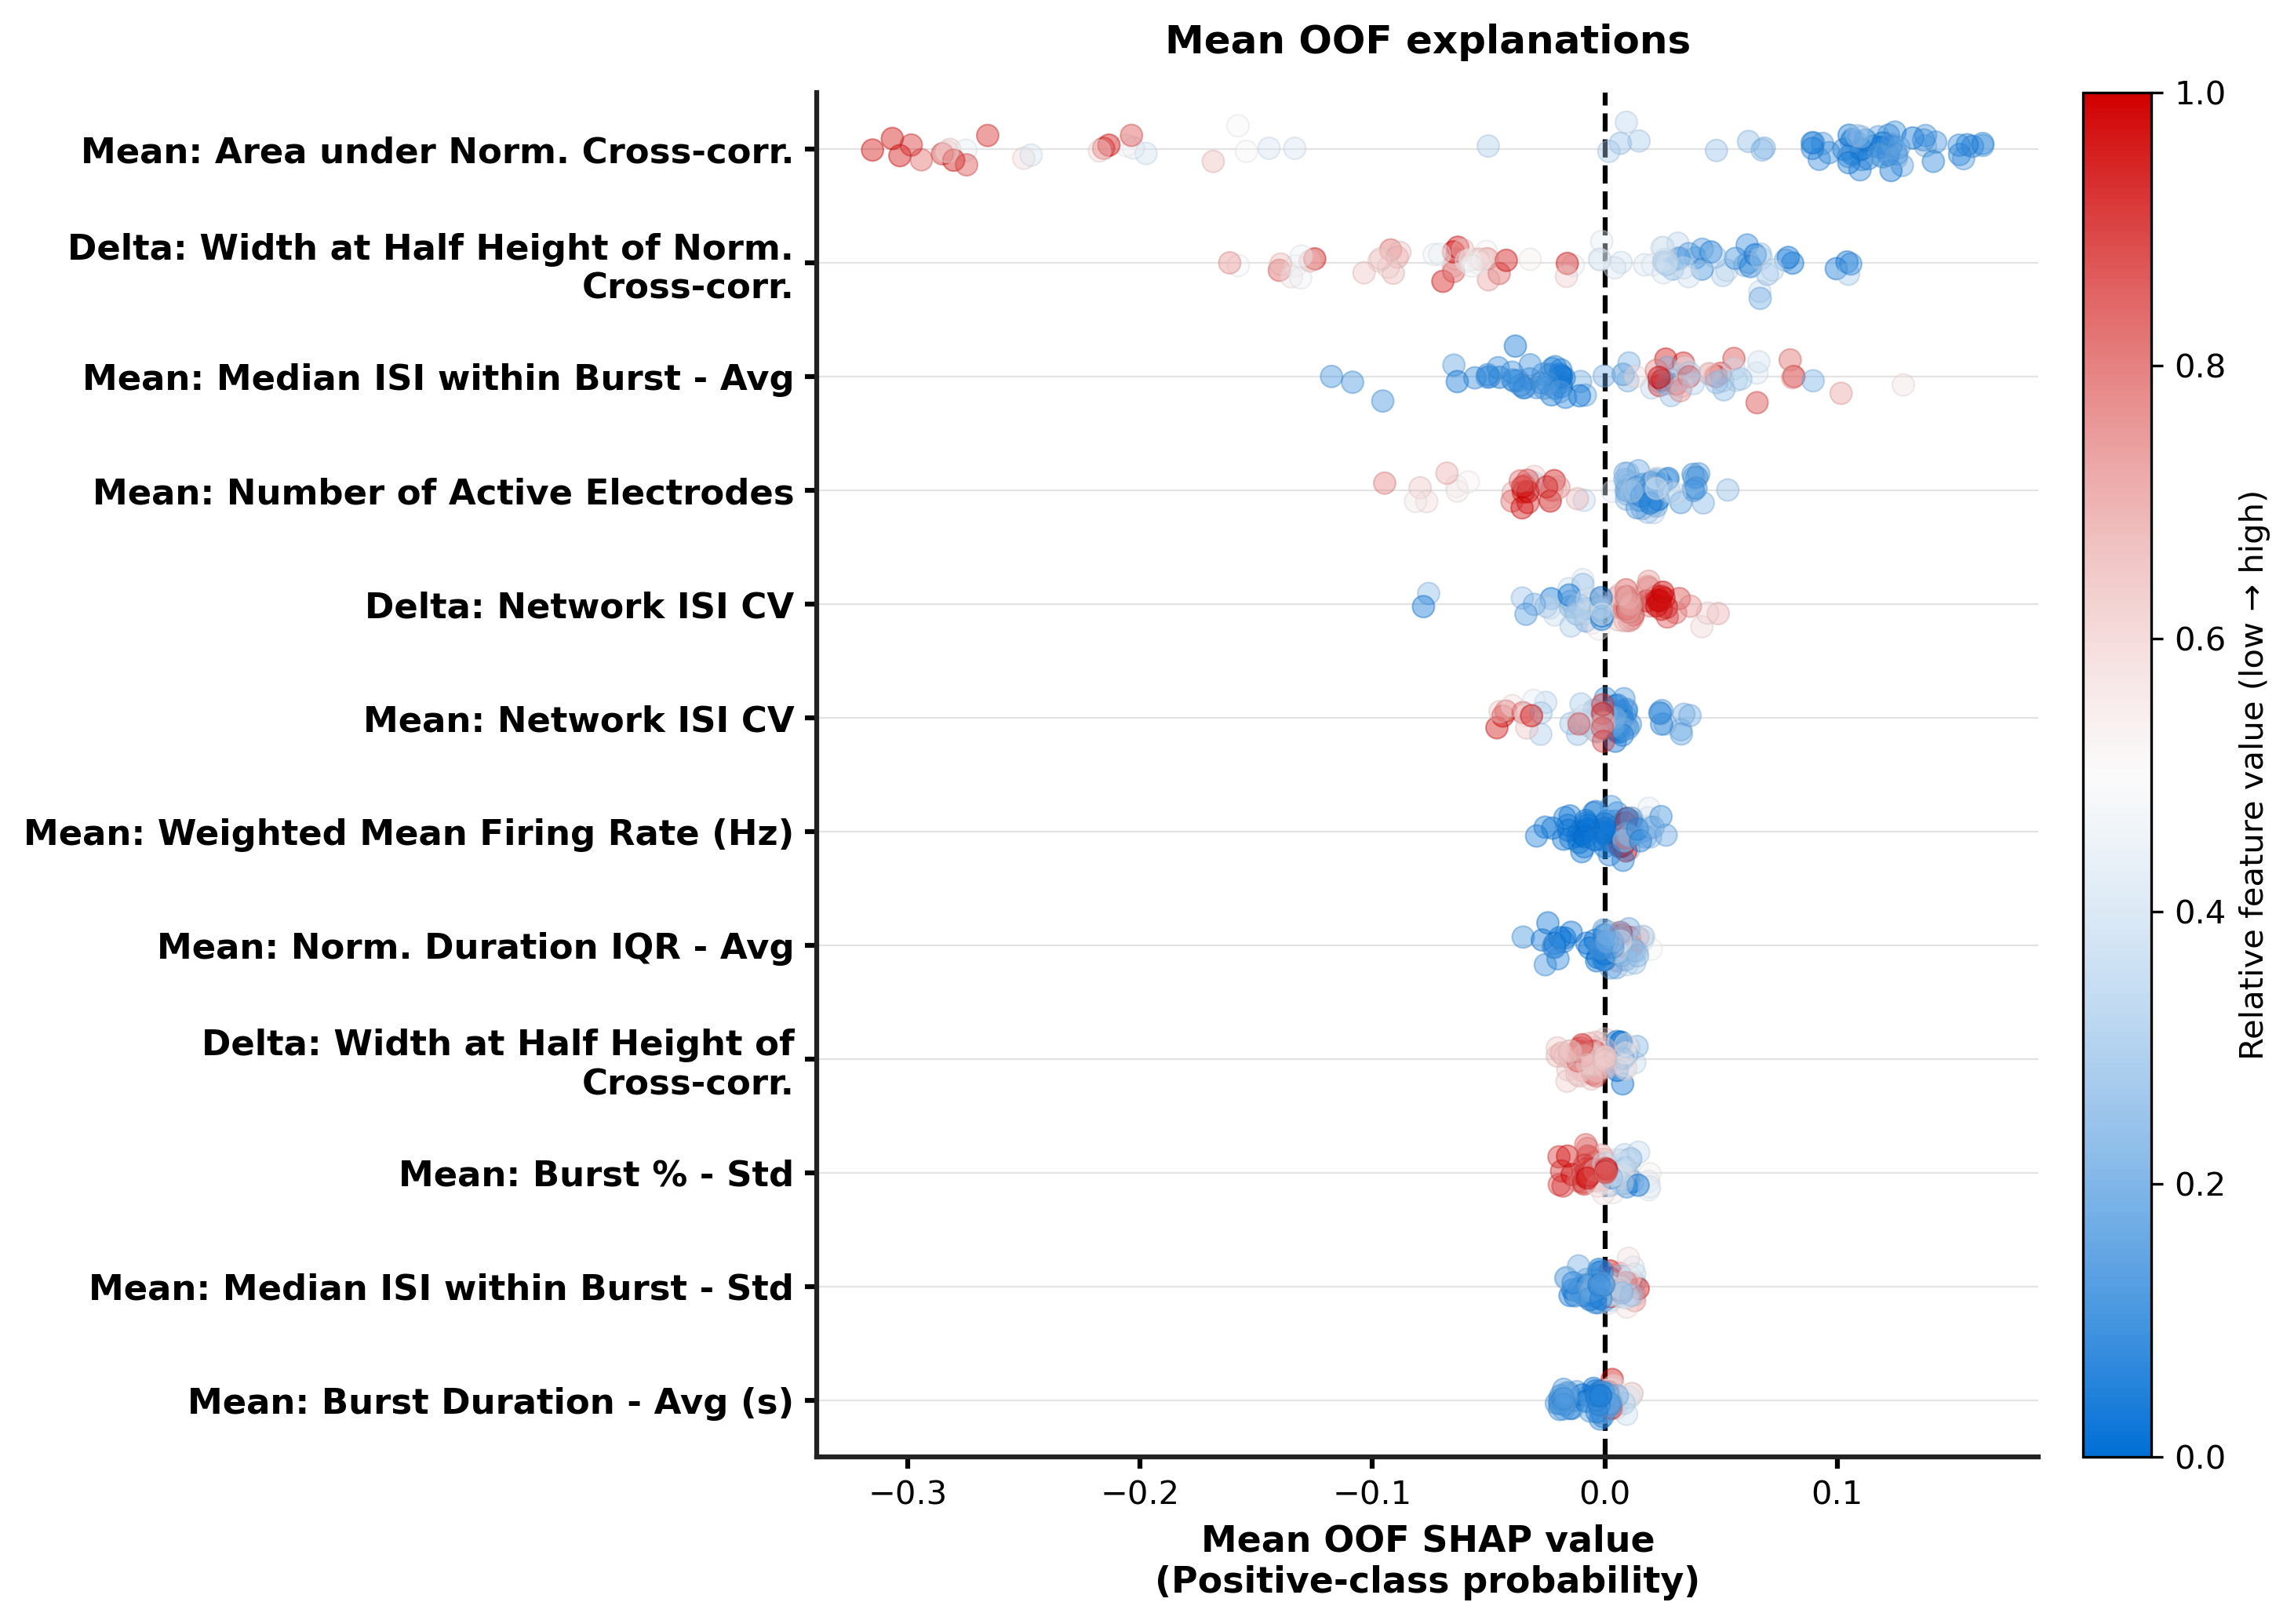

Saved: results/07_figure5/fig5_shap_summary.png


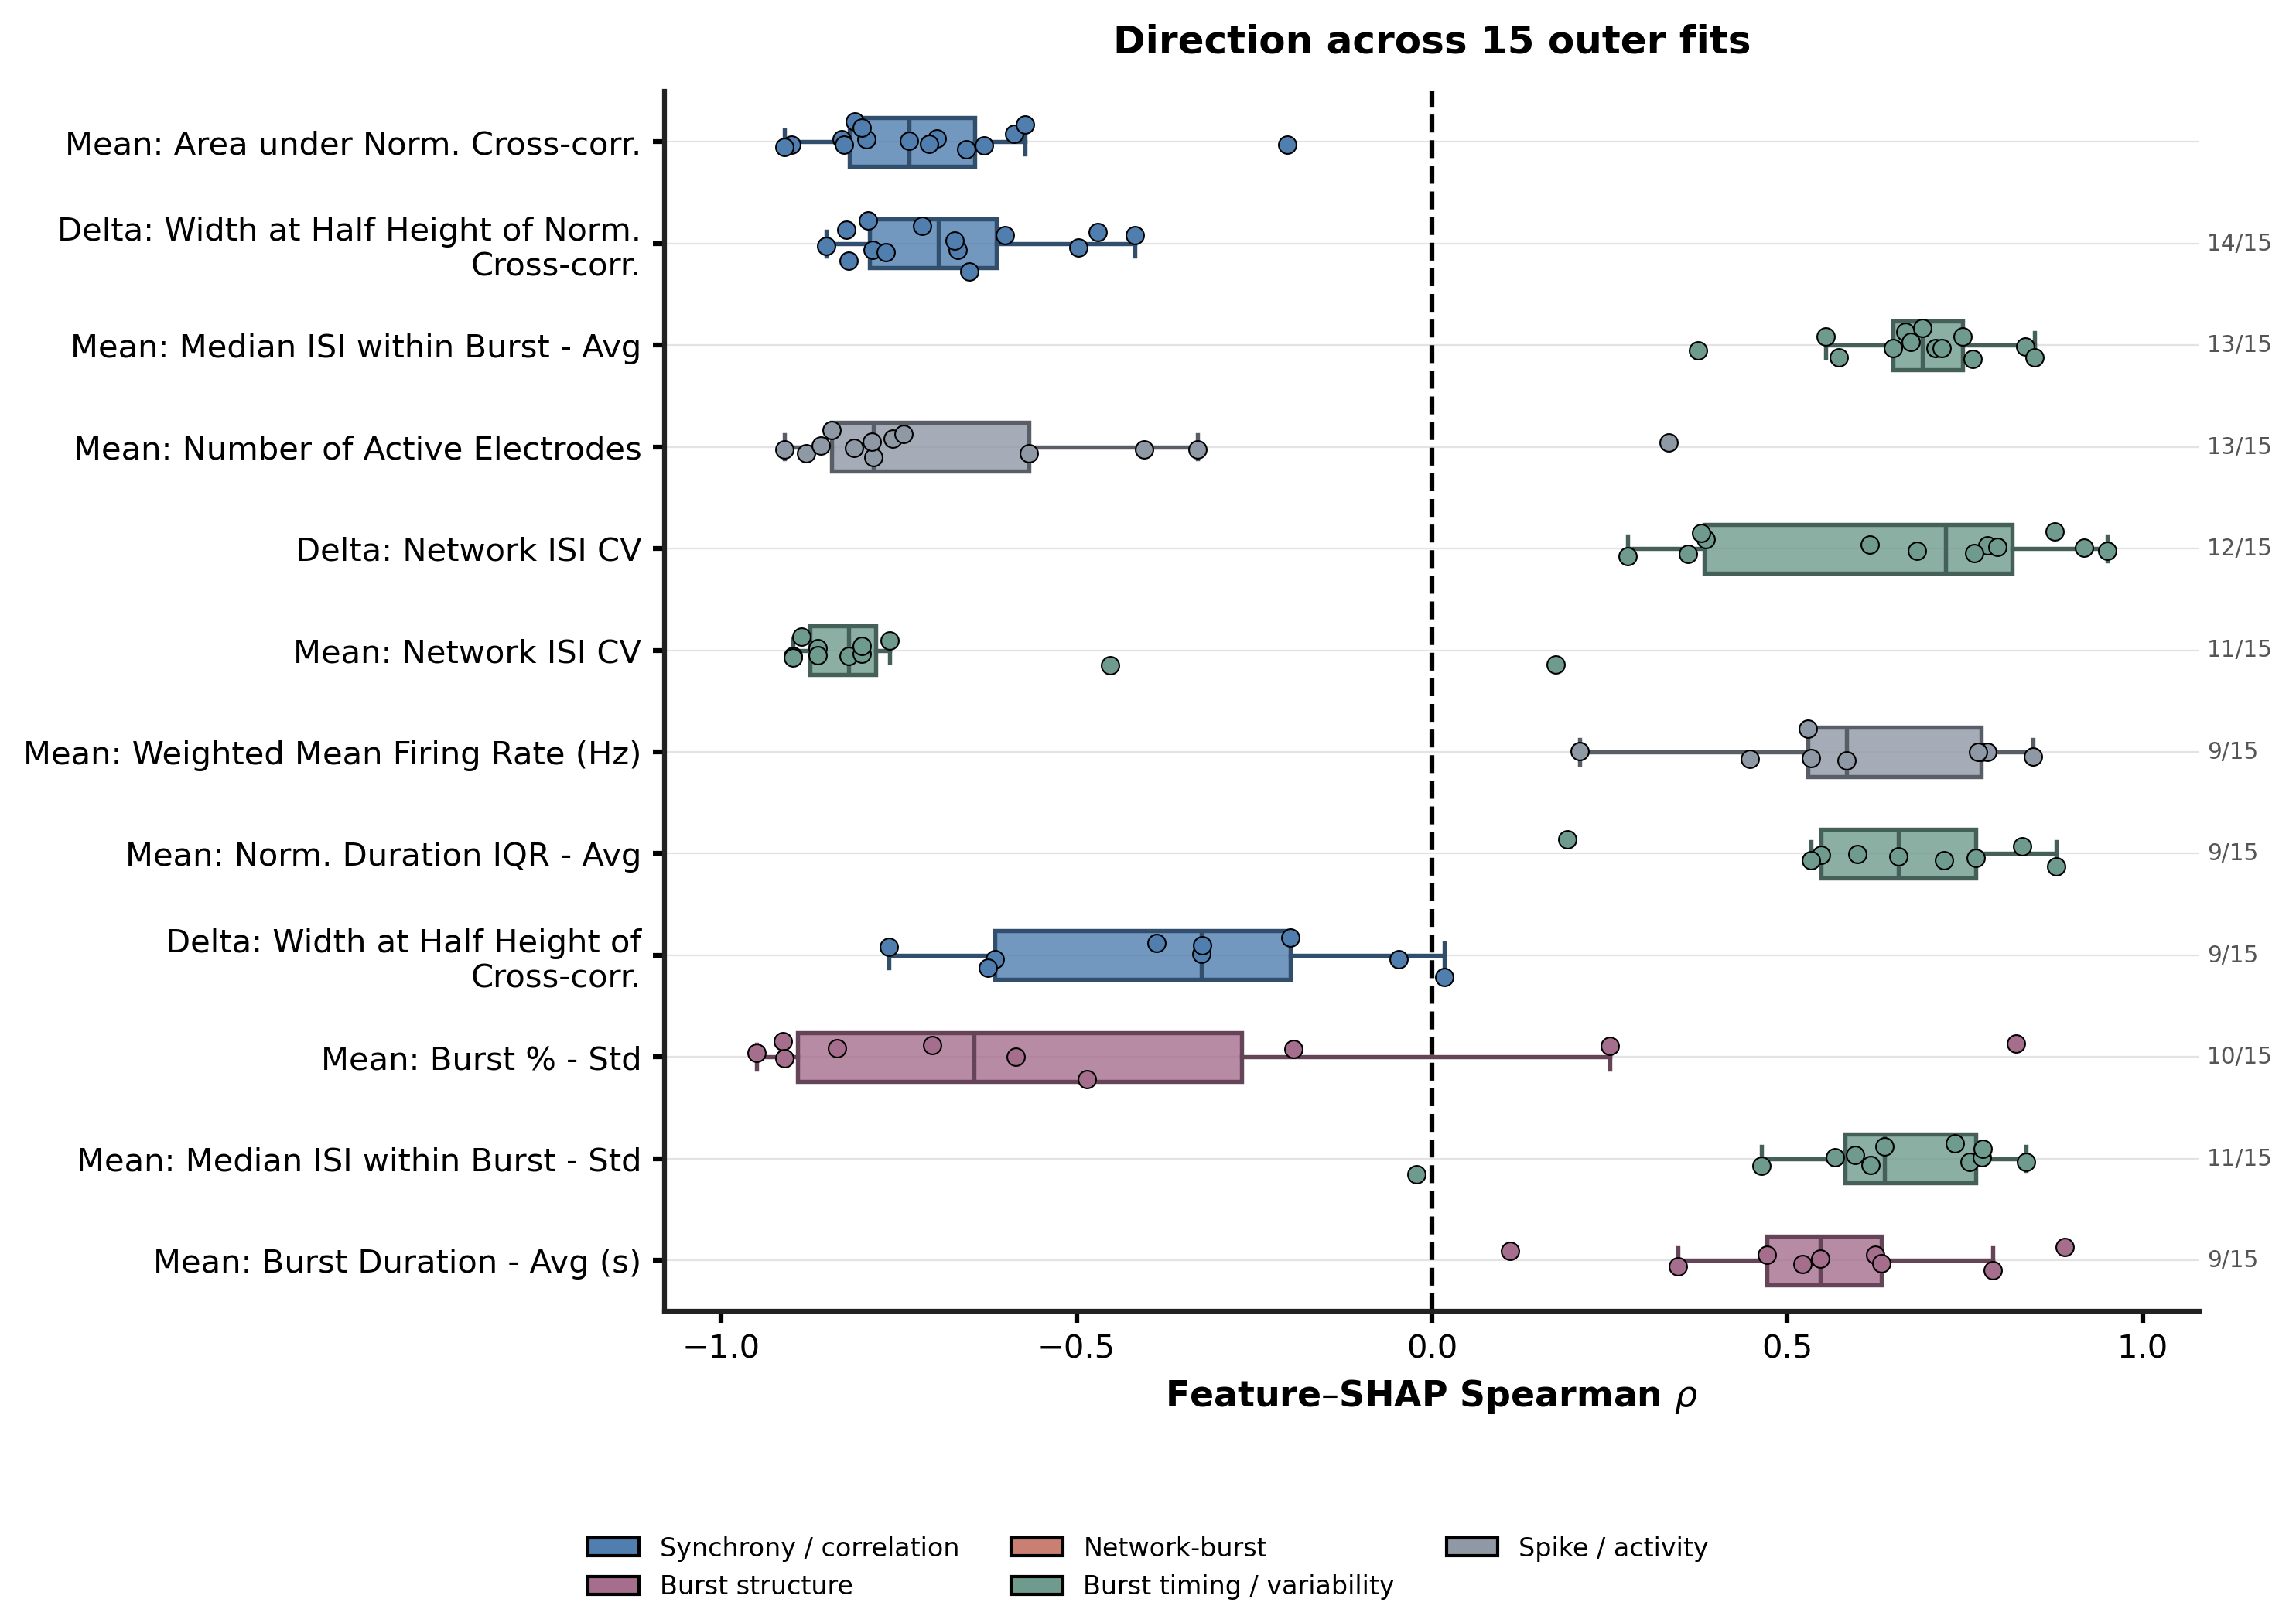

Saved: results/07_figure5/fig5_shap_direction.png


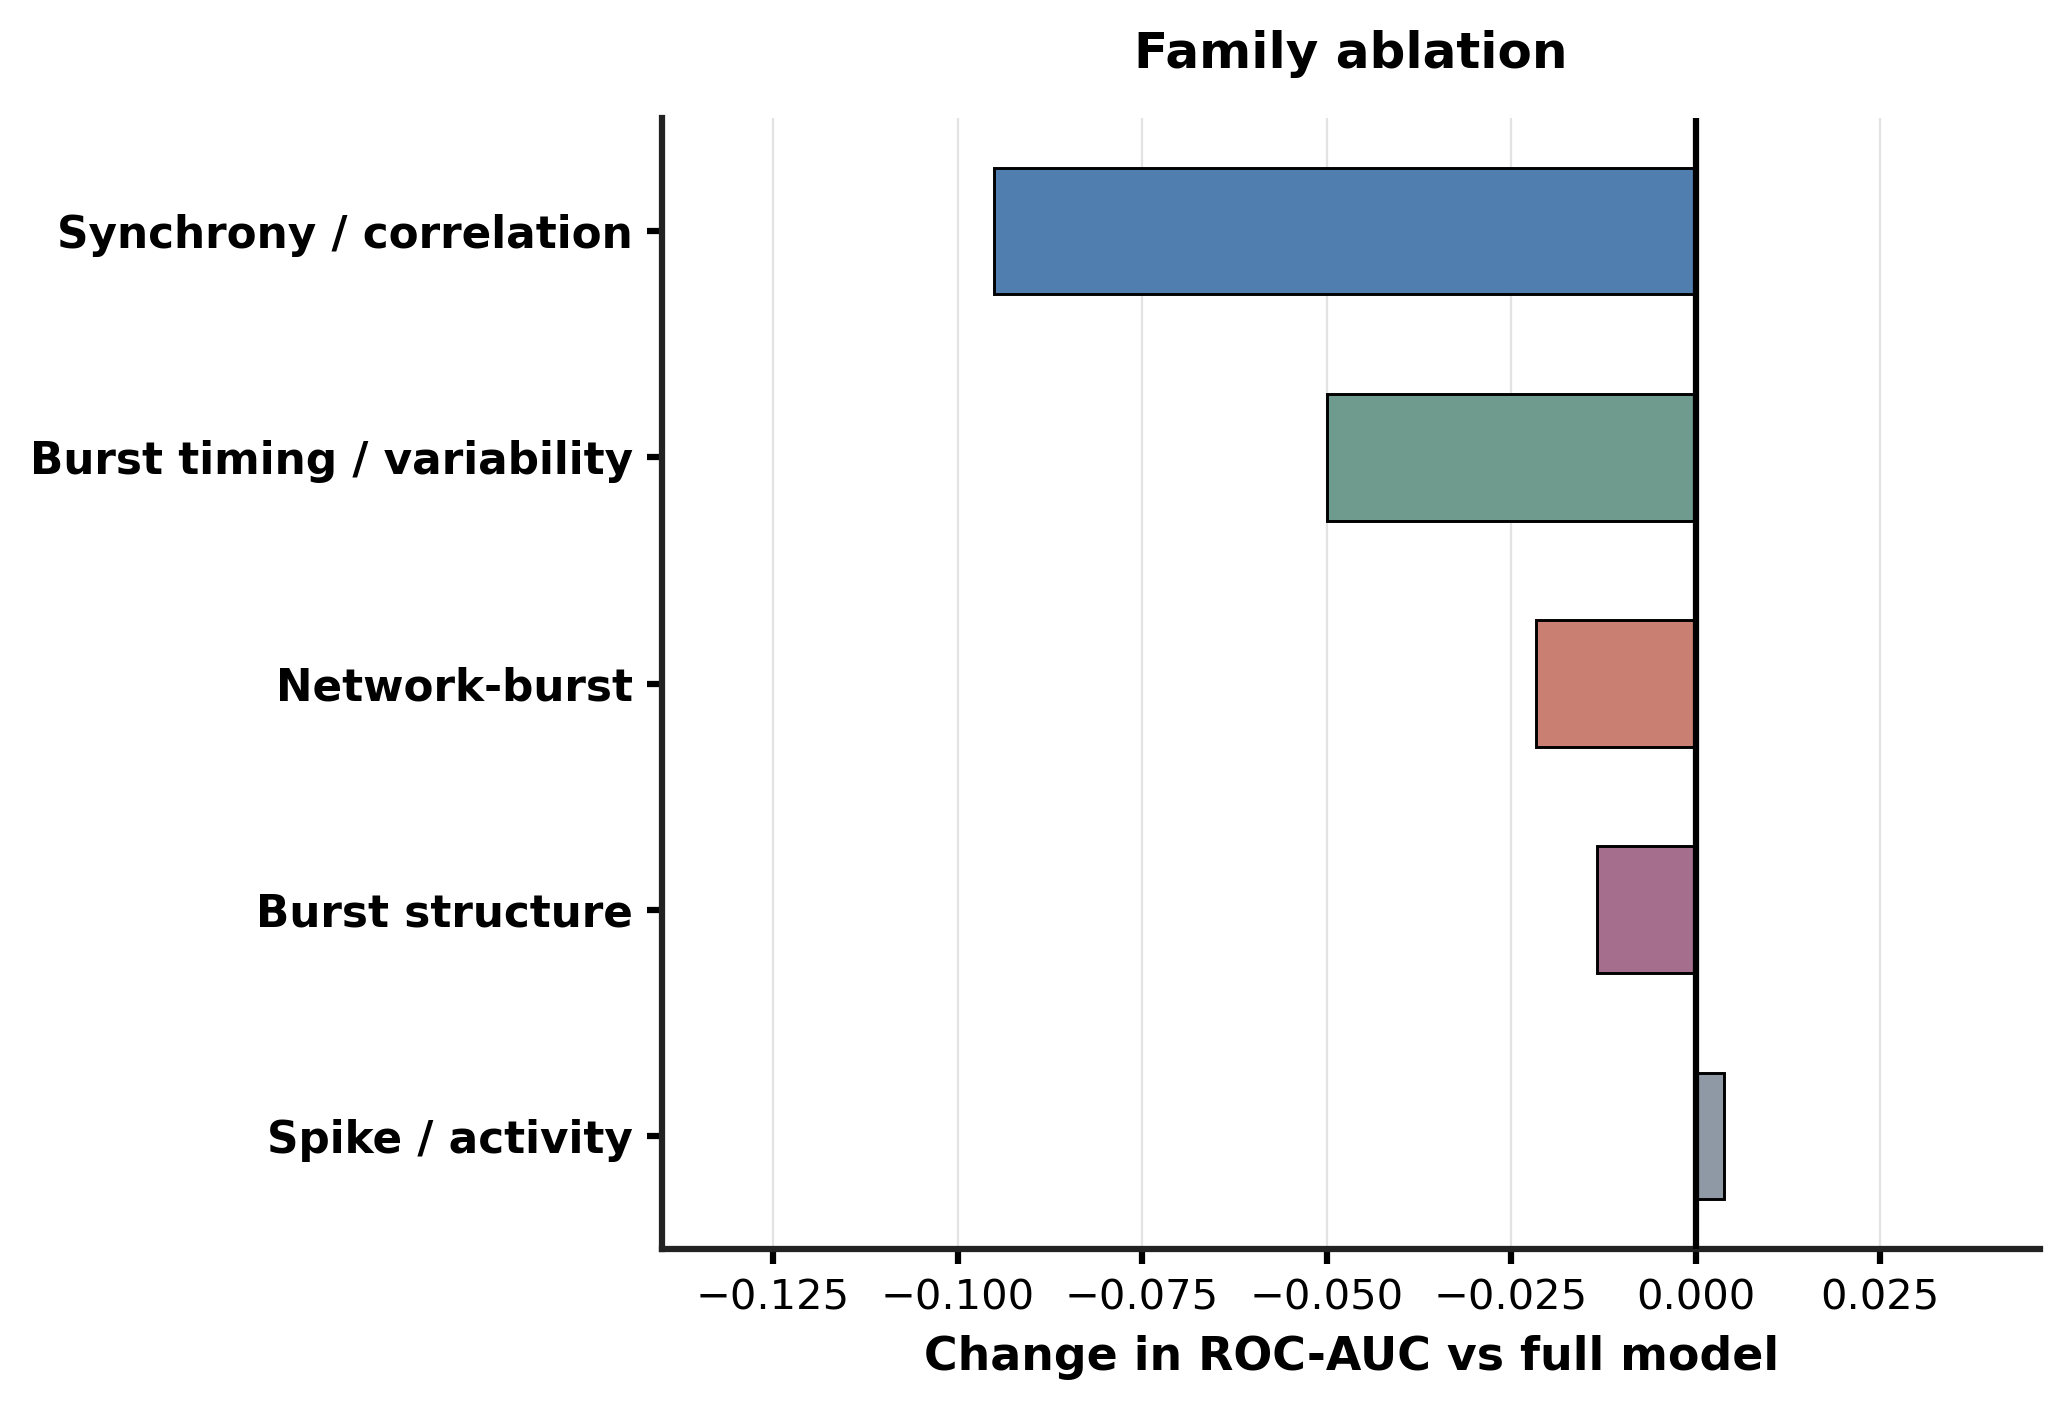

Saved: results/07_figure5/fig5_family_ablation.png


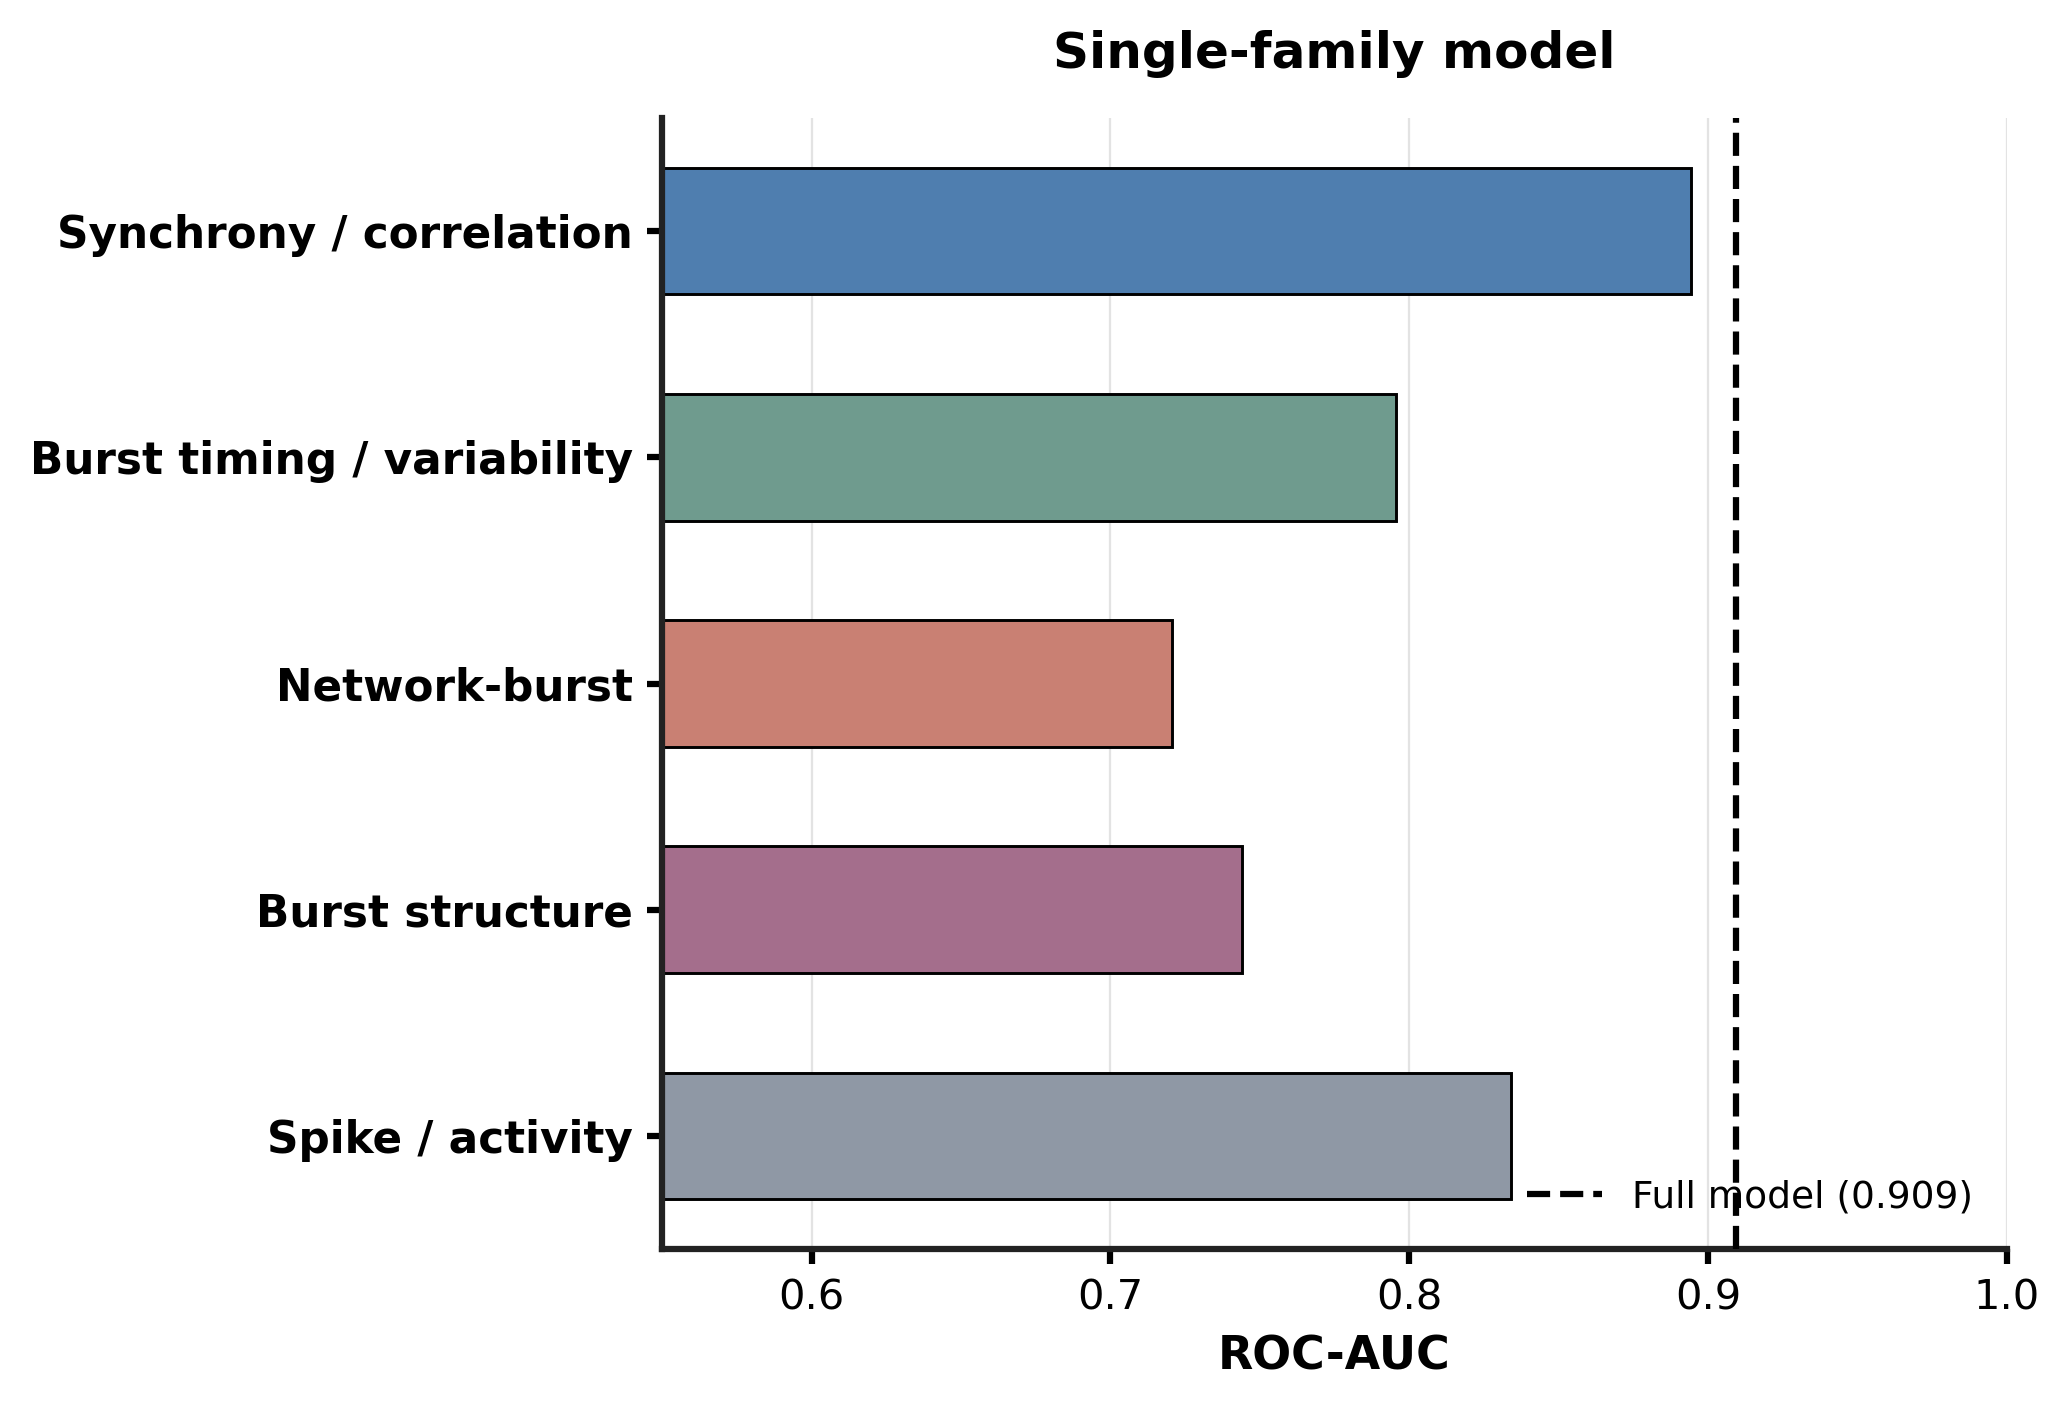

Saved: results/07_figure5/fig5_single_family.png


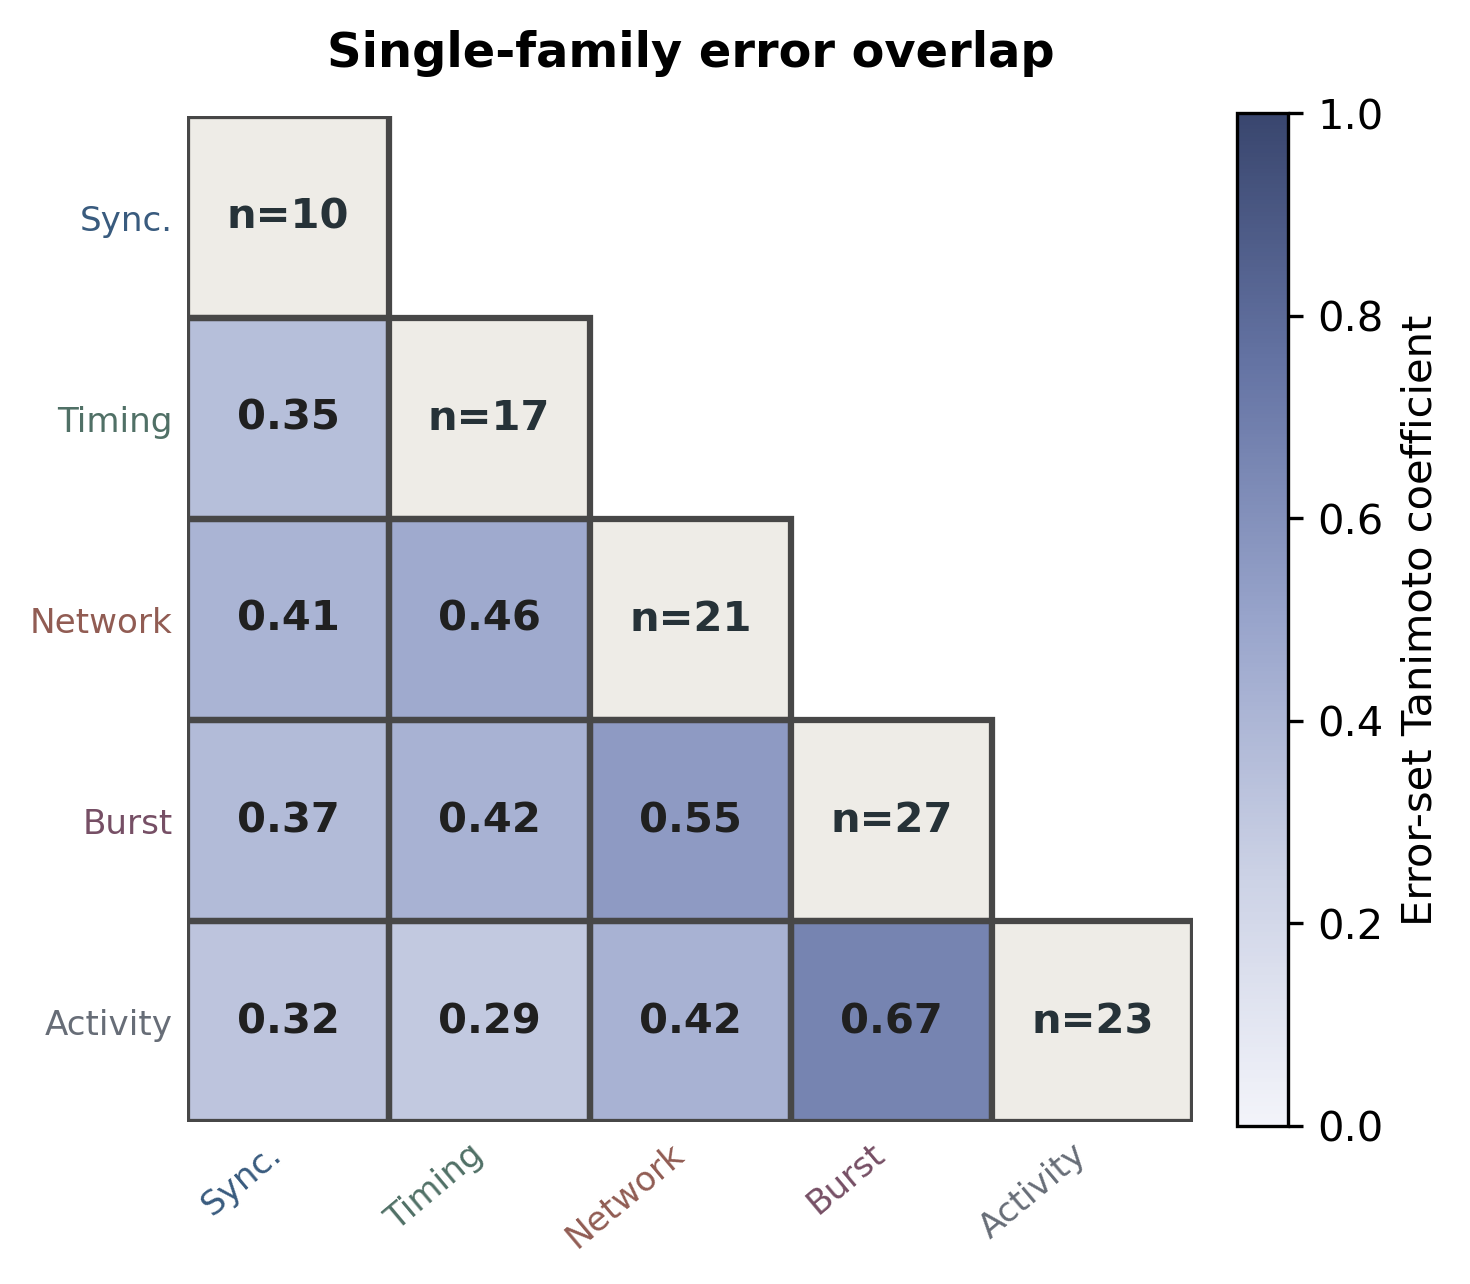

Saved: results/07_figure5/fig5_error_overlap.png


,feature_name,median,n_estimable_fits,n_undefined_fits,n_positive_fits,n_negative_fits
0,Mean::Burst Duration - Avg (s),0.545924,9,6,9,0
1,Mean::Median ISI within Burst - Std,0.636739,11,4,10,1
2,Mean::Burst Percentage - Std,-0.643963,10,5,2,8
3,Delta::Width at Half Height of Cross-Correlation,-0.324213,9,6,1,8
4,Mean::Normalized Duration IQR - Avg,0.656672,9,6,9,0
5,Mean::Weighted Mean Firing Rate (Hz),0.583075,9,6,9,0
6,Mean::Network ISI Coefficient of Variation,-0.820433,11,4,1,10
7,Delta::Network ISI Coefficient of Variation,0.722394,12,3,12,0
8,Mean::Number of Active Electrodes,-0.785751,13,2,1,12
9,Mean::Median ISI within Burst - Avg,0.689764,13,2,13,0


In [4]:
feature_order_main = shap_feature_ranking.head(12).feature_name.tolist()[::-1]
family_handles = [Patch(facecolor=FAMILY_COLORS[f], edgecolor="black", label=FAMILY_LABELS[f])
                  for f in ["synchrony_correlation", "burst", "network_burst", "burst_timing", "spike_activity"]]

fig, ax = plt.subplots(figsize=(10, 7))
points = plot_main_shap(ax, feature_order_main)
fig.colorbar(points, ax=ax, pad=0.03).set_label("Relative feature value (low → high)")
fig.tight_layout()
save_png(fig, OUT_DIR, "fig5_shap_summary")

fig, ax = plt.subplots(figsize=(10, 7))
plot_shap_direction(ax, feature_order_main)
fig.legend(handles=family_handles, loc="lower center", ncol=3, frameon=False, fontsize=8)
fig.tight_layout(rect=[0, 0.10, 1, 1])
save_png(fig, OUT_DIR, "fig5_shap_direction")

fig, ax = plt.subplots(figsize=(7, 4.8))
plot_family_performance(ax, "leave_one_family_out")
fig.tight_layout()
save_png(fig, OUT_DIR, "fig5_family_ablation")

fig, ax = plt.subplots(figsize=(7, 4.8))
plot_family_performance(ax, "family_only")
ax.plot([], [], color="black", ls="--", label=f"Full model ({full_auc:.3f})")
ax.legend(frameon=False, loc="lower right", fontsize=9)
fig.tight_layout()
save_png(fig, OUT_DIR, "fig5_single_family")

fig, ax = plt.subplots(figsize=(5, 5))
image = plot_family_error_overlap(ax)
fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04).set_label("Error-set Tanimoto coefficient")
fig.tight_layout()
save_png(fig, OUT_DIR, "fig5_error_overlap")

direction_boxplot_summary = summarize_direction(feature_order_main)
direction_points_source = shap_direction_by_fit[shap_direction_by_fit.feature_name.isin(feature_order_main)].copy()
display(direction_boxplot_summary[["feature_name", "median", "n_estimable_fits", "n_undefined_fits",
                                   "n_positive_fits", "n_negative_fits"]])


## Save figure source data

In [5]:
figure_summary={
    "lineage":lineage,"selected_model_name":selected_model,"selected_feature_set":selected_feature_set,
    "plot_images": ["fig5_shap_summary.png", "fig5_shap_direction.png", "fig5_family_ablation.png",
                    "fig5_single_family.png", "fig5_error_overlap.png"],
    "n_unique_wells":int(shap_mean_df.sample_index.nunique()),"n_outer_fits":N_FITS,
    "error_overlap":{"definition":"size of intersection / size of union of misclassified-well sets",
        "threshold":DECISION_THRESHOLD,"aggregation":"one mean OOF probability per well across repeats",
        "empty_union":"undefined (NA)","diagonal":"error counts; not color-coded",
        "display":"strict lower triangle; diagonal counts; duplicate upper triangle blank",
        "source_matrix":"full symmetric matrix retained in CSV",
        "family_order":"same as the family-performance panels; no clustering",
        "scope":"descriptive error overlap; threshold- and error-count-dependent; not proof of complementarity or integration benefit"},
    "probability_scale_shap":True,
    "direction_metric":"Spearman(feature_value, signed positive-probability SHAP), separately within each outer held-out fold",
    "direction_shap_constant_tolerance":SHAP_DIRECTION_ATOL,
    "direction_boxplot":"Q1-Q3 box, median, Tukey 1.5-IQR whiskers; every estimable fit shown including outliers",
    "direction_undefined_handling":"undefined correlations kept as NaN with reason and counts; never assigned zero",
    "direction_status_counts":{str(k):int(v) for k,v in direction_points_source.direction_status.value_counts().items()},
    "direction_scope":"descriptive monotonic association, not coefficient/effect size/importance/causal effect; near-zero rho can hide non-monotonic patterns",
    "direction_inference":"overlapping CV fits; no independence assumption, confidence intervals, or p-values",
    "boxplot_whis":BOXPLOT_WHIS,"direction_axis_limits":[-1.08,1.08],
    "wells_removed_from_performance":0,
    "full_pooled_auroc":full_auc,
    "decision_threshold":DECISION_THRESHOLD,
    "max_mean_additivity_error":float(well_predictions.additivity_error.max()),
}
(OUT_DIR/"figure5_summary.json").write_text(json.dumps(figure_summary,indent=2),encoding="utf-8")
shap_mean_df[shap_mean_df.feature_name.isin(feature_order_main)].to_csv(OUT_DIR/'figure5_panelA_shap_source.csv',index=False)
direction_points_source.to_csv(OUT_DIR/'figure5_panelA_direction_by_outer_fit.csv',index=False)
direction_boxplot_summary.to_csv(OUT_DIR/'figure5_panelA_direction_boxplot_statistics.csv',index=False)
family_summary[family_summary.analysis_type.isin(["leave_one_family_out","family_only"])].to_csv(OUT_DIR/'figure5_panelB_family_source.csv',index=False)
well_predictions.to_csv(OUT_DIR/'figure5_prediction_additivity_audit.csv',index=False)
family_error_overlap.to_csv(OUT_DIR/'figure5_panelC_error_overlap_details.csv',index=False)
error_jaccard_matrix.to_csv(OUT_DIR/'figure5_panelC_error_overlap_matrix.csv')
family_error_counts.to_csv(OUT_DIR/'figure5_panelC_error_counts.csv',index=False)
family_error_source.to_csv(OUT_DIR/'figure5_panelC_error_source_by_well.csv',index=False)
print("Saved Figure 5 and source tables:",OUT_DIR.relative_to(PROJECT_ROOT))


Saved Figure 5 and source tables: results/07_figure5
